In [5]:
import numpy as np
import matplotlib.pyplot as plt
from optical_transmission_system.components import *

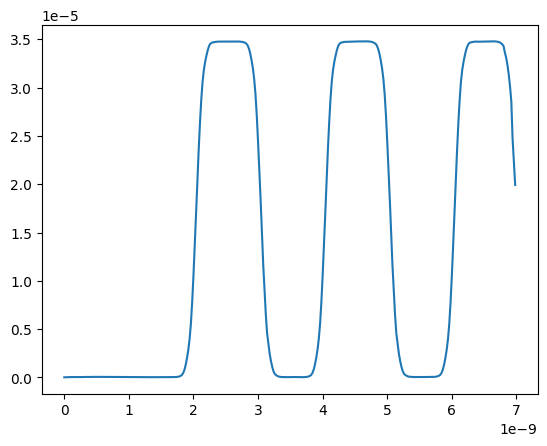

In [9]:
system = System(components=[
    NRZEncoder(sampling_rate=50e9),
    ElectricalLowPassFilter(order=5, cutoff_frequency=3e9),
    AWGN(power=2e-6),
    PulseAmplitudeModulator(
        carrier_source=Transmitter(power=2e-3, linewidth=10e9, frequency_count=128),
        order=1
    ),
    OpticalChannel(attenuation=0.22, length=80, chromatic_dispersion=17),
])

input_signal = Signal.digital(samples=np.array([0, 0, 1, 0, 1, 0, 1]), data_rate=1e9)
output_signal = system(input_signal)
 
plt.plot(output_signal.timing.time, np.sum(output_signal.samples**2, axis=1, dtype="float32"))

In [10]:
np.sum(output_signal.samples**2) / len(output_signal.samples)

np.float32(1.451979e-05)

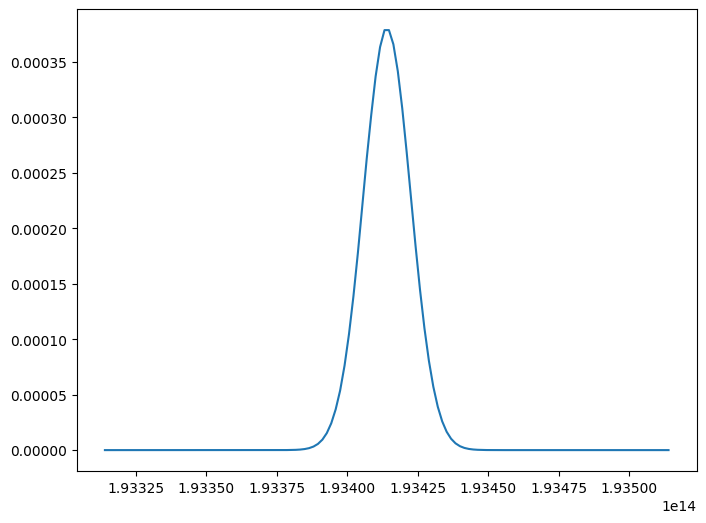

In [11]:
plt.figure(figsize=(8, 6))
plt.plot(output_signal.frequencies, np.sum(output_signal.samples.transpose()**2, axis=1))